# PCL Detection

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from transformers import AutoTokenizer, RobertaModel, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    confusion_matrix, precision_recall_curve, average_precision_score,
)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import html, re, random, warnings, os, ast
from tqdm import tqdm

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def clean_text(text):
    if pd.isna(text) or not isinstance(text, str): return ""
    return re.sub(r'\\s+', ' ', html.unescape(text)).strip()

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

/mnt/c/Users/adars/Desktop/nlp_cw/nlp/nlp_cw/proj/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


## Data Loading & Splitting

We load the DontPatronizeMe dataset and merge with the official SemEval train/dev splits.  
- **Binary label**: 0 if annotation score ∈ {0,1}, 1 if score ∈ {2,3,4}  
- **Soft label**: raw score / 4 (used later by the regression head)  
- **Multi-label**: 7 fine-grained PCL category flags per paragraph

In [2]:
df_raw = pd.read_csv(
    '../data/dontpatronizeme_pcl.tsv', sep='\t', skiprows=4,
    names=['par_id','art_id','keyword','country_code','text','label'],
    on_bad_lines='skip',
)
df_raw['text']         = df_raw['text'].apply(clean_text)
df_raw['label']        = pd.to_numeric(df_raw['label'], errors='coerce').fillna(0).astype(int)
df_raw['binary_label'] = (df_raw['label'] >= 2).astype(int)
df_raw['soft_label']   = df_raw['label'] / 4.0

train_ids = pd.read_csv('../data/train_semeval_parids-labels.csv')
dev_ids   = pd.read_csv('../data/dev_semeval_parids-labels.csv')
train_ids['multi_label'] = train_ids['label'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
dev_ids['multi_label']   = dev_ids['label'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
for d in [df_raw, train_ids, dev_ids]: d['par_id'] = d['par_id'].astype(str)

df_train_full = pd.merge(df_raw, train_ids[['par_id','multi_label']], on='par_id', how='inner')
df_dev        = pd.merge(df_raw, dev_ids[['par_id','multi_label']],   on='par_id', how='inner')

df_train, df_val = train_test_split(
    df_train_full, test_size=0.15,
    stratify=df_train_full['binary_label'], random_state=42,
)
df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_dev.reset_index(drop=True)

# ── Class-imbalance weights ──────────────────────────────────────────────────
labels_array = np.array(df_train['multi_label'].tolist())
pos_counts   = labels_array.sum(axis=0)
neg_counts   = len(labels_array) - pos_counts
weight_multi = np.sqrt(neg_counts / (pos_counts + 1e-9)).astype(np.float32)
bin_pos      = int(df_train['binary_label'].sum())
weight_bin   = float(np.sqrt((len(df_train) - bin_pos) / (bin_pos + 1e-9)))

total = len(df_train)
print(f"Train: {total} samples  |  PCL positive: {bin_pos} ({100*bin_pos/total:.1f}%)  |  Negative: {total-bin_pos} ({100*(total-bin_pos)/total:.1f}%)")
print(f"Val  : {len(df_val)}  |  Test: {len(df_test)}")

Train: 7118 samples  |  PCL positive: 675 (9.5%)  |  Negative: 6443 (90.5%)
Val  : 1257  |  Test: 2094


## Visualise Class Imbalance 

The chart below makes the case for WeightedRandomSampler  
With vanilla random batching, a typical batch of 16 contains only ~1–2 positives.

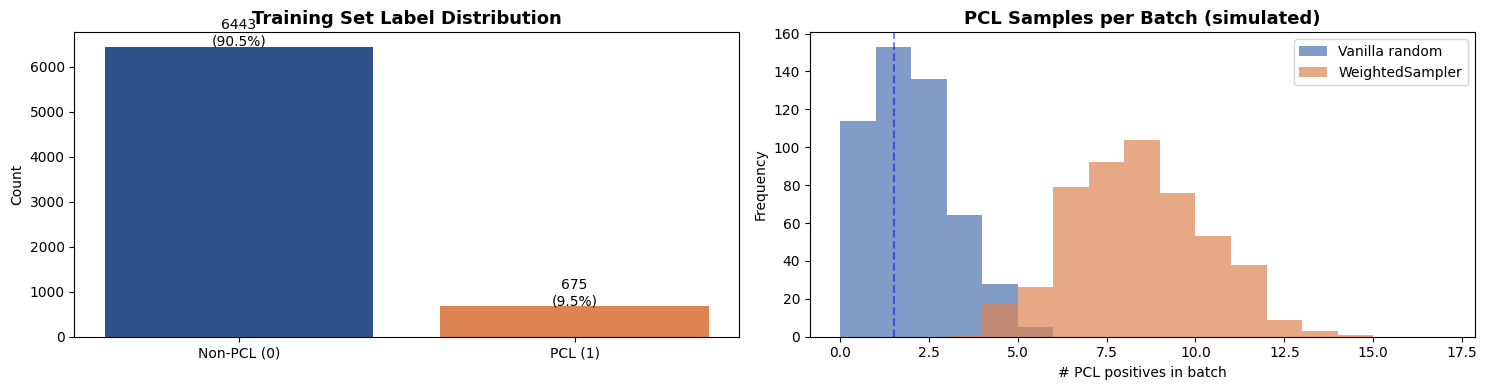

Mean PCL per vanilla batch: 1.52 / 16
With WeightedSampler:       8.0 / 16 (balanced)


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# 1. Overall label distribution
counts = df_train['binary_label'].value_counts().sort_index()
axes[0].bar(['Non-PCL (0)', 'PCL (1)'], counts.values, color=["#2F528B",'#DD8452'])
axes[0].set_title('Training Set Label Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, f'{v}\n({100*v/counts.sum():.1f}%)', ha='center', fontsize=10)

# 2. Vanilla random vs weighted sampler batch composition (simulated)
np.random.seed(42)
n_batches = 500
batch_size = 16
pos_frac   = bin_pos / total
vanilla_pos_per_batch  = np.random.binomial(batch_size, pos_frac,    n_batches)
balanced_pos_per_batch = np.random.binomial(batch_size, 0.5, n_batches)
axes[1].hist(vanilla_pos_per_batch,  bins=range(0, batch_size+2), alpha=0.7, color='#4C72B0', label='Vanilla random')
axes[1].hist(balanced_pos_per_batch, bins=range(0, batch_size+2), alpha=0.7, color='#DD8452', label='WeightedSampler')
axes[1].set_title('PCL Samples per Batch (simulated)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('# PCL positives in batch'); axes[1].set_ylabel('Frequency')
axes[1].legend(); axes[1].axvline(x=pos_frac*batch_size, color='blue', ls='--', alpha=0.5)


plt.tight_layout()
plt.savefig('motivation_charts.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Mean PCL per vanilla batch: {pos_frac*batch_size:.2f} / {batch_size}")
print(f"With WeightedSampler:       {0.5*batch_size:.1f} / {batch_size} (balanced)")

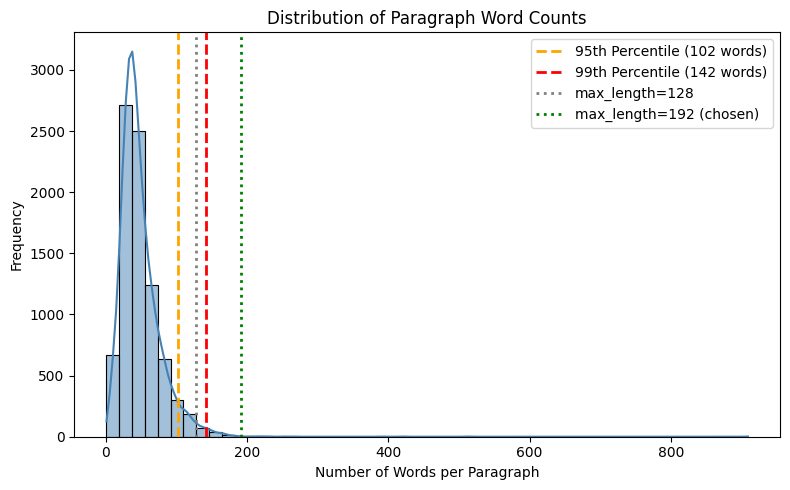

Word Count Statistics:
count    8375.000000
mean       48.675224
std        29.677952
min         1.000000
25%        30.000000
50%        42.000000
75%        60.000000
max       909.000000
Name: word_count, dtype: float64

95th Percentile : 102.0 words
99th Percentile : 142.0 words
Paragraphs exceeding 128 words: 1.7%
Paragraphs exceeding 192 words: 0.1%


In [27]:
df_train_full['word_count'] = df_train_full['text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(8, 5))
sns.histplot(df_train_full['word_count'], bins=50, kde=True, color='steelblue')
plt.title('Distribution of Paragraph Word Counts')
plt.xlabel('Number of Words per Paragraph')
plt.ylabel('Frequency')

p95  = df_train_full['word_count'].quantile(0.95)
p99  = df_train_full['word_count'].quantile(0.99)
plt.axvline(p95, color='orange', linestyle='--', linewidth=2, label=f'95th Percentile ({int(p95)} words)')
plt.axvline(p99, color='red',    linestyle='--', linewidth=2, label=f'99th Percentile ({int(p99)} words)')
plt.axvline(128, color='gray',   linestyle=':',  linewidth=2, label='max_length=128')
plt.axvline(192, color='green',  linestyle=':',  linewidth=2, label='max_length=192 (chosen)')
plt.legend()
plt.tight_layout()
plt.savefig('length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("Word Count Statistics:")
print(df_train_full['word_count'].describe())
print(f"\n95th Percentile : {p95:.1f} words")
print(f"99th Percentile : {p99:.1f} words")
pct_over_128 = 100 * (df_train_full['word_count'] > 128).mean()
pct_over_192 = 100 * (df_train_full['word_count'] > 192).mean()
print(f"Paragraphs exceeding 128 words: {pct_over_128:.1f}%")
print(f"Paragraphs exceeding 192 words: {pct_over_192:.1f}%")

## Visualise Layer-wise LR Decay

Lower RoBERTa layers encode general syntactic and morphological patterns from pretraining.  
Applying the same high LR to all layers causes **catastrophic forgetting** of this knowledge.  
LLRD uses `lr_i = lr_base × decay^(num_layers − 1 − i)` so earlier layers change minimally.

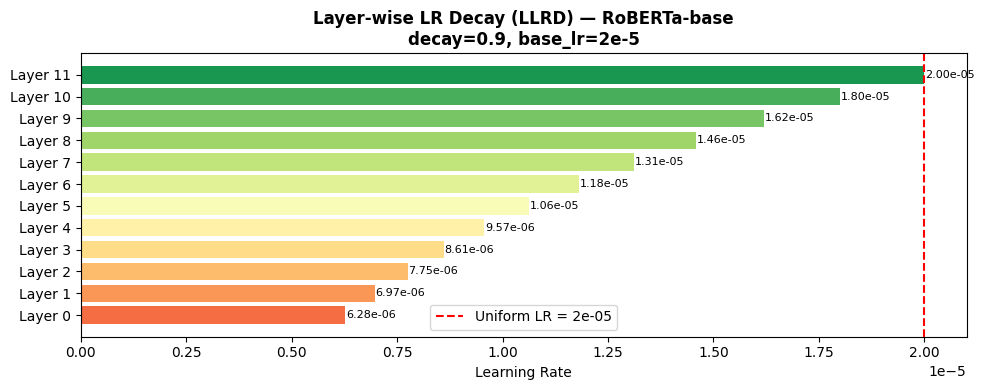

Layer 0  (embeddings): LR = 6.2762e-06  ← syntax/morphology — barely updated
Layer 11 (top layer):  LR = 2.0000e-05  ← task semantics    — updated fully


In [4]:
num_layers = 12
base_lr    = 2e-5
decay      = 0.9

lrs   = [base_lr * (decay ** (num_layers - 1 - i)) for i in range(num_layers)]
names = [f'Layer {i}' for i in range(num_layers)]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(names, lrs, color=plt.cm.RdYlGn(np.linspace(0.2, 0.9, num_layers)))
ax.axvline(x=base_lr, color='red', ls='--', lw=1.5, label=f'Uniform LR = {base_lr:.0e}')
ax.set_xlabel('Learning Rate'); ax.set_title('Layer-wise LR Decay (LLRD) — RoBERTa-base\ndecay=0.9, base_lr=2e-5', fontweight='bold')
ax.legend()
for bar, lr in zip(bars, lrs):
    ax.text(bar.get_width() + 2e-8, bar.get_y() + bar.get_height()/2,
            f'{lr:.2e}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('llrd_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("Layer 0  (embeddings): LR =", f"{lrs[0]:.4e}  ← syntax/morphology — barely updated")
print("Layer 11 (top layer):  LR =", f"{lrs[-1]:.4e}  ← task semantics    — updated fully")

## Architecture Components

1) WeightedRandomSampler
2) Focal Loss
3) Concat Pooling (CLS ⊕ mean ⊕ max)
4) Layer-wise LR Decay (LLRD)
5) Keyword-Conditioned Attention 



In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# WeightedRandomSampler helper
# ══════════════════════════════════════════════════════════════════════════════
def make_weighted_sampler(binary_labels: np.ndarray) -> WeightedRandomSampler:
    """Over-samples positives so every batch is ~50/50 by construction."""
    class_counts   = np.bincount(binary_labels)
    class_weights  = 1.0 / (class_counts + 1e-9)
    sample_weights = class_weights[binary_labels]
    return WeightedRandomSampler(
        weights     = torch.tensor(sample_weights, dtype=torch.float),
        num_samples = len(sample_weights),
        replacement = True,
    )


# ══════════════════════════════════════════════════════════════════════════════
#  Focal Loss
# ══════════════════════════════════════════════════════════════════════════════
class FocalLoss(nn.Module):
    """
    Binary Focal Loss: FL(p_t) = -(1 - p_t)^gamma * log(p_t)
    alpha weights the positive class (set ≈ pos_class_frequency for imbalance).
    """
    def __init__(self, alpha: float = 0.25, gamma: float = 2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        bce   = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        p_t   = torch.exp(-bce)
        loss  = ((1 - p_t) ** self.gamma) * bce
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * loss).mean()


# ══════════════════════════════════════════════════════════════════════════════
# Concat Pooler  (CLS ⊕ mean ⊕ max)
# ══════════════════════════════════════════════════════════════════════════════
class ConcatPooler(nn.Module):
    """
    Concatenates three pooling strategies over RoBERTa hidden states.
    Output dimension: 3 × hidden_size (requires a projection layer downstream).
    """
    def forward(self, hidden_states: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        cls_out  = hidden_states[:, 0, :]

        mask_exp = attention_mask.unsqueeze(-1).float()
        mean_out = (hidden_states * mask_exp).sum(1) / mask_exp.sum(1).clamp(min=1e-9)

        masked   = hidden_states.masked_fill(mask_exp == 0, -1e9)
        max_out  = masked.max(dim=1).values

        return torch.cat([cls_out, mean_out, max_out], dim=-1)   # (B, 3H)


# ══════════════════════════════════════════════════════════════════════════════
# Keyword-Conditioned Attention Gate 
# ══════════════════════════════════════════════════════════════════════════════
class KCAG(nn.Module):
    """
    Keyword-Conditioned Attention Gate.

    Given:
        hidden_states  : (B, T, H) — full token representations from RoBERTa
        attention_mask : (B, T)    — 1 for real tokens, 0 for padding
        kw_hidden      : (B, H)    — keyword representation (mean-pool of kw tokens)

    Computes per-token gates:
        g_i = sigmoid( W_gate · concat(h_i, kw) + b_gate )    ∈ (0,1)

    Output:
        pooled = Σ_i  g_i * h_i                                shape (B, H)

    Intuition: the keyword tells the model which group is discussed;
    the gate then highlights tokens that are most indicative of condescension
    towards that group. 
    """
    def __init__(self, hidden_size: int):
        super().__init__()
        # Maps concat(h_i, kw) → scalar gate
        self.W_gate = nn.Linear(hidden_size * 2, 1)
        nn.init.xavier_uniform_(self.W_gate.weight)
        nn.init.zeros_(self.W_gate.bias)

    def forward(
        self,
        hidden_states:  torch.Tensor,   
        attention_mask: torch.Tensor,   
        kw_hidden:      torch.Tensor,   
    ) -> torch.Tensor:                  
        B, T, H = hidden_states.shape

        kw_exp  = kw_hidden.unsqueeze(1).expand(B, T, H)
        concat  = torch.cat([hidden_states, kw_exp], dim=-1)
        gates   = torch.sigmoid(self.W_gate(concat))

        mask_exp = attention_mask.unsqueeze(-1).float()  
        gates    = gates * mask_exp

       
        pooled   = (gates * hidden_states).sum(dim=1)

        gate_sum = gates.sum(dim=1).clamp(min=1e-9)      
        pooled   = pooled / gate_sum

        return pooled


# ══════════════════════════════════════════════════════════════════════════════
# Layer-wise LR Decay helper
# ══════════════════════════════════════════════════════════════════════════════
def get_llrd_param_groups(model: nn.Module, base_lr: float, head_lr: float, decay: float = 0.9):
    """
    Returns AdamW param groups with layer-wise decayed learning rates.
    Layer 0 (embeddings): lr = base_lr × decay^11  (smallest)
    Layer 11 (top):       lr = base_lr              (largest backbone lr)
    Heads:                lr = head_lr              (can be larger)
    """
    n = model.roberta.config.num_hidden_layers    # 12
    groups = []

    # Embedding layer
    groups.append({'params': list(model.roberta.embeddings.parameters()),
                   'lr': base_lr * (decay ** n), 'name': 'embeddings'})

    # Transformer blocks
    for i, layer in enumerate(model.roberta.encoder.layer):
        groups.append({'params': list(layer.parameters()),
                       'lr': base_lr * (decay ** (n - 1 - i)),
                       'name': f'encoder.{i}'})

    # Task-specific modules
    for attr in ['proj', 'kcag', 'pooler', 'bin_head', 'multi_head', 'reg_head']:
        if hasattr(model, attr):
            groups.append({'params': list(getattr(model, attr).parameters()),
                           'lr': head_lr, 'name': attr})

    return groups


## Dataset

In [7]:
class PCLDataset(Dataset):
    """
    Returns tokenised examples with entity-marker wrapping (when enabled)
    and a SEPARATE encoding of just the keyword string for KCAG.
    """
    def __init__(self, df, tokenizer, flags, max_length: int = 192):
        self.texts           = df['text'].tolist()
        self.keywords        = df['keyword'].tolist()
        self.multi_labels    = df['multi_label'].tolist()
        self.binary_labels   = df['binary_label'].tolist()
        self.soft_labels     = df['soft_label'].tolist()
        self.original_labels = df['label'].tolist()
        self.tokenizer       = tokenizer
        self.flags           = flags
        self.max_length      = max_length

    def __len__(self): return len(self.texts)

    def _prep_keyword(self, raw):
        kw = str(raw).replace('-', ' ').lower().strip()
        return 'vulnerable group' if kw in ('nan', '', 'none') else kw

    def __getitem__(self, idx):
        text    = self.texts[idx]
        keyword = self._prep_keyword(self.keywords[idx])

        # ── Text preprocessing ───────────────────────────────────────────────
        if self.flags.get('use_entity_markers', False):
            pat = re.compile(f'(?i)({re.escape(keyword)})')
            if pat.search(text):
                text = pat.sub(r'[E1] \1 [/E1]', text)
            else:
                text = f"[E1] {keyword} [/E1] : {text}"
        elif self.flags.get('include_keyword_context', False):
            text = f"{keyword} </s></s> {text}"

        enc = self.tokenizer(text, truncation=True, padding='max_length',
                             max_length=self.max_length, return_tensors='pt')

        # ── Separate keyword encoding for KCAG ───────────────────────────────
        kw_enc = self.tokenizer(keyword, truncation=True, padding='max_length',
                                max_length=16, return_tensors='pt')

        return {
            'input_ids':       enc['input_ids'].flatten(),
            'attention_mask':  enc['attention_mask'].flatten(),
            'kw_input_ids':    kw_enc['input_ids'].flatten(),
            'kw_attention_mask': kw_enc['attention_mask'].flatten(),
            'multi_label':     torch.tensor(self.multi_labels[idx],    dtype=torch.float),
            'binary_label':    torch.tensor(self.binary_labels[idx],   dtype=torch.float),
            'soft_label':      torch.tensor(self.soft_labels[idx],     dtype=torch.float),
            'original_label':  torch.tensor(self.original_labels[idx], dtype=torch.long),
        }



## ModularModel to run abalation experiments

The model is fully modular: every component can be toggled via the `flags` dict.  

In [8]:
class ModularModel(nn.Module):
    """
    Modular RoBERTa model for PCL detection.
    """
    def __init__(self, model_name: str, vocab_size: int, flags: dict, config: dict):
        super().__init__()
        self.flags   = flags
        self.roberta = RobertaModel.from_pretrained(model_name)
        self.roberta.resize_token_embeddings(vocab_size)
        H = self.roberta.config.hidden_size    # 768

        # ── Pooling ──────────────────────────────────────────────────────────
        if flags.get('use_kcag', False):
            self.kcag    = KCAG(H)
            feat_dim     = H
        elif flags.get('use_concat_pooling', False):
            self.pooler  = ConcatPooler()
            feat_dim     = 3 * H
        else:
            feat_dim     = H   # CLS only

        # ── Projection: maps feat_dim → proj_dim before heads 
        proj_dim = config.get('proj_dim', H)
        self.proj = nn.Sequential(
            nn.Linear(feat_dim, proj_dim),
            nn.GELU(),
            nn.Dropout(config.get('dropout_rate', 0.3)),
        )

        # Task heads 
        self.bin_head = nn.Linear(proj_dim, 1)
        if flags.get('use_mtl', False):
            self.multi_head = nn.Linear(proj_dim, 7)
        if flags.get('use_reg', False):
            self.reg_head = nn.Linear(proj_dim, 1)

    # ── Internal encoder shared by text and keyword 
    def _encode(self, input_ids, attention_mask):
        return self.roberta(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state

    def forward(self, input_ids, attention_mask, kw_input_ids=None, kw_attention_mask=None):
        hs = self._encode(input_ids, attention_mask) 

        if self.flags.get('use_kcag', False):
            #    encode the keyword tokens through the SAME RoBERTa encoder
            kw_hs  = self._encode(kw_input_ids, kw_attention_mask)      
            #   mean-pool keyword tokens → single keyword vector k
            kw_mask = kw_attention_mask.unsqueeze(-1).float()
            kw_vec  = (kw_hs * kw_mask).sum(1) / kw_mask.sum(1).clamp(min=1e-9)     
            #  gate main hidden states with keyword vector
            feat    = self.kcag(hs, attention_mask, kw_vec)             

        elif self.flags.get('use_concat_pooling', False):
            feat = self.pooler(hs, attention_mask)                      

        else:
            feat = hs[:, 0, :]    # CLS token                       

        feat     = self.proj(feat)  
        b_logits = self.bin_head(feat).squeeze(-1)
        m_logits = self.multi_head(feat) if self.flags.get('use_mtl', False) else None
        r_logits = self.reg_head(feat).squeeze(-1) if self.flags.get('use_reg', False) else None

        return b_logits, m_logits, r_logits


## Cell 8 — Experiment Runner

In [10]:
def run_experiment(name, flags, config, model_save_path=None, csv_save_path=None):
    """
    Full train/val/test cycle. Returns (test_f1, best_threshold).
    """
   
    print(f"\n{'='*60}")
    print(f"  {name}")
    print(f"{'='*60}")
    set_seed(42)

    tokenizer = AutoTokenizer.from_pretrained('roberta-base')
    if flags.get('use_entity_markers', False):
        tokenizer.add_tokens(['[E1]', '[/E1]'])

    max_len  = config.get('max_length', 192)
    ds_train = PCLDataset(df_train, tokenizer, flags, max_len)
    ds_val   = PCLDataset(df_val,   tokenizer, flags, max_len)
    ds_test  = PCLDataset(df_test,  tokenizer, flags, max_len)

    # WeightedRandomSampler
    if flags.get('use_sampler', False):
        sampler      = make_weighted_sampler(df_train['binary_label'].values)
        loader_train = DataLoader(ds_train, batch_size=config['batch_size'], sampler=sampler)
    else:
        loader_train = DataLoader(ds_train, batch_size=config['batch_size'], shuffle=True)
    loader_val  = DataLoader(ds_val,  batch_size=config['batch_size']*2, shuffle=False)
    loader_test = DataLoader(ds_test, batch_size=config['batch_size']*2, shuffle=False)

    model = ModularModel('roberta-base', len(tokenizer), flags, config).to(device)

    # LLRD
    if flags.get('use_llrd', False):
        param_groups = get_llrd_param_groups(
            model, config['lr_backbone'], config['lr_head'],
            decay=config.get('llrd_decay', 0.9)
        )
    else:
        param_groups = [
            {'params': model.roberta.parameters(), 'lr': config['lr_backbone']},
        ]
        for attr in ['proj','kcag','pooler','bin_head','multi_head','reg_head']:
            if hasattr(model, attr):
                param_groups.append({'params': getattr(model, attr).parameters(),
                                     'lr': config['lr_head']})

    optimizer    = torch.optim.AdamW(param_groups, weight_decay=0.01)
    total_steps  = len(loader_train) * config['epochs']
    scheduler    = get_linear_schedule_with_warmup(
        optimizer, int(total_steps * 0.1), total_steps
    )

    # IMP-2: Loss function selection
    if flags.get('use_focal', False):
        # alpha = observed positive rate 
        fa = float(bin_pos / len(df_train)) if flags.get('use_weights', False) else config.get('focal_alpha', 0.25)
        crit_bin = FocalLoss(alpha=fa, gamma=config.get('focal_gamma', 2.0))
    elif flags.get('use_weights', False):
        crit_bin = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(weight_bin, dtype=torch.float).to(device)
        )
    else:
        crit_bin = nn.BCEWithLogitsLoss()

    crit_multi = (
        nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weight_multi, dtype=torch.float).to(device))
        if flags.get('use_weights', False) else nn.BCEWithLogitsLoss()
    )

    w_bin   = config['w_bin']
    w_multi = config['w_multi']
    w_reg   = config['w_reg']

    best_f1, best_t, patience_ctr = 0.0, 0.5, 0
    best_state = None
    train_losses, val_f1s = [], []

    for epoch in range(config['epochs']):
        model.train()
        ep_loss = 0.0
        optimizer.zero_grad()

        for b in tqdm(loader_train, desc=f"Ep {epoch+1}", leave=False):
            ids   = b['input_ids'].to(device)
            mask  = b['attention_mask'].to(device)
            blabs = b['binary_label'].to(device)
            kw_ids  = b['kw_input_ids'].to(device)
            kw_mask = b['kw_attention_mask'].to(device)

            b_log, m_log, r_log = model(ids, mask, kw_ids, kw_mask)
            loss = w_bin * crit_bin(b_log, blabs)

            if flags.get('use_mtl', False) and m_log is not None:
                loss = loss + w_multi * crit_multi(m_log, b['multi_label'].to(device))

            if flags.get('use_reg', False) and r_log is not None:
                pcl_mask = blabs == 1
                if pcl_mask.sum() > 0:
                    loss = loss + w_reg * F.binary_cross_entropy_with_logits(
                        r_log[pcl_mask], b['soft_label'].to(device)[pcl_mask], reduction='mean'
                    )

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            ep_loss += loss.item()

        train_losses.append(ep_loss / len(loader_train))

        # ── Validation ───────────────────────────────────────────────────────
        model.eval()
        v_probs, v_labs = [], []
        with torch.no_grad():
            for b in loader_val:
                logits, _, _ = model(
                    b['input_ids'].to(device), b['attention_mask'].to(device),
                    b['kw_input_ids'].to(device), b['kw_attention_mask'].to(device)
                )
                v_probs.extend(torch.sigmoid(logits).cpu().numpy())
                v_labs.extend(b['binary_label'].numpy())

        cur_f1, cur_t = 0.0, 0.5
        for t in np.linspace(0.1, 0.9, 81):
            f = f1_score(v_labs, (np.array(v_probs) >= t).astype(int), zero_division=0)
            if f > cur_f1: cur_f1, cur_t = f, t
        val_f1s.append(cur_f1)

        print(f"  Epoch {epoch+1} | loss={train_losses[-1]:.4f} | Val F1={cur_f1:.4f} (t={cur_t:.2f})")

        if cur_f1 > best_f1:
            best_f1, best_t, patience_ctr = cur_f1, cur_t, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= config['patience']:
                print(f"  Early stop.")
                break

    # ── Test evaluation ───────────────────────────────────────────────────────
    if model_save_path:
        torch.save(best_state, model_save_path)

    model.load_state_dict(best_state)
    model.eval()
    t_probs, t_labs, o_labs = [], [], []
    with torch.no_grad():
        for b in loader_test:
            logits, _, _ = model(
                b['input_ids'].to(device), b['attention_mask'].to(device),
                b['kw_input_ids'].to(device), b['kw_attention_mask'].to(device)
            )
            t_probs.extend(torch.sigmoid(logits).cpu().numpy())
            t_labs.extend(b['binary_label'].numpy())
            o_labs.extend(b['original_label'].numpy())

    t_probs  = np.array(t_probs)
    preds    = (t_probs >= best_t).astype(int)
    final_f1 = f1_score(t_labs, preds, zero_division=0)
    prec     = precision_score(t_labs, preds, zero_division=0)
    rec      = recall_score(t_labs, preds, zero_division=0)
    print(f"\n  ► Val F1={best_f1:.4f} | Test F1={final_f1:.4f} | P={prec:.4f} | R={rec:.4f} | t={best_t:.2f}")

    if csv_save_path:
        res = df_test.copy()
        res['tamn_pred']                = preds
        res['tamn_prob']                = t_probs
        res['ground_truth_binary']      = t_labs
        res['original_severity_0_to_4'] = o_labs
        res['error_type'] = 'True Negative'
        res.loc[(res['ground_truth_binary']==1)&(res['tamn_pred']==1), 'error_type'] = 'True Positive'
        res.loc[(res['ground_truth_binary']==0)&(res['tamn_pred']==1), 'error_type'] = 'False Positive'
        res.loc[(res['ground_truth_binary']==1)&(res['tamn_pred']==0), 'error_type'] = 'False Negative'
        res.to_csv(csv_save_path, index=False)

    return final_f1, best_t, {'train_losses': train_losses, 'val_f1s': val_f1s}


## Baseline Config & Ablation Study

Each experiment adds **exactly one** new component to the previous best configuration.  
This incremental design allows us to attribute F1 changes to individual components.

| Exp | What's added | Purpose |
|-----|-------------|---------|
| 0 | Vanilla RoBERTa-base (no weights) | True baseline |
| 1 | + WeightedRandomSampler | Fix data-level imbalance |
| 2 | + Focal Loss | Fix loss-level imbalance |
| 3 | + Concat Pooling (CLS⊕mean⊕max) | Richer representation |
| 4 | + Layer-wise LR Decay | Safer fine-tuning |
| 5 | + KCAG | Group-conditional attention |


In [ ]:


base_config = {
    'lr_backbone':  2e-5,
    'lr_head':      1e-4,
    'llrd_decay':   0.9,
    'batch_size':   16,
    'epochs':       10,
    'patience':     5,
    'dropout_rate': 0.3,
    'proj_dim':     768, 
    'max_length':   192,
    'w_bin':        1.0,
    'w_multi':      0.3,
    'w_reg':        0.15,
    'focal_gamma':  2.0,
    'focal_alpha':  0.25,
}

concat_config = {**base_config, 'proj_dim': 512}

results        = {}    # exp_name -> test_f1
training_curves = {}  # exp_name -> {train_losses, val_f1s}



## Baseline Roberta model

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, RobertaModel
from sklearn.metrics import f1_score, confusion_matrix
import warnings, os, random
from tqdm import tqdm

warnings.filterwarnings("ignore")

def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class BaselineDataset(Dataset):
    def __init__(self, df, tokenizer):
        self.texts           = df['text'].tolist()
        self.binary_labels   = df['binary_label'].tolist()
        self.original_labels = df['label'].tolist()  
        self.tokenizer       = tokenizer

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        if not isinstance(text, str): text = ""
        enc = self.tokenizer(text, truncation=True, padding='max_length',
                             max_length=128, return_tensors='pt')
        return {
            'input_ids':      enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'binary_label':   torch.tensor(self.binary_labels[idx],   dtype=torch.float),
            'original_label': torch.tensor(self.original_labels[idx], dtype=torch.long),
        }


class BaselineRoberta(nn.Module):
    def __init__(self, model_name='roberta-base'):
        super().__init__()
        self.roberta    = RobertaModel.from_pretrained(model_name)
        self.classifier = nn.Linear(self.roberta.config.hidden_size, 1)

    def forward(self, input_ids, attention_mask):
        outputs   = self.roberta(input_ids=input_ids, attention_mask=attention_mask)
        cls_token = outputs.last_hidden_state[:, 0, :]
        return self.classifier(cls_token).squeeze(-1)


tokenizer_v    = AutoTokenizer.from_pretrained('roberta-base')
loader_train_v = DataLoader(BaselineDataset(df_train, tokenizer_v), batch_size=16,   shuffle=True)
loader_val_v   = DataLoader(BaselineDataset(df_val,   tokenizer_v), batch_size=32, shuffle=False)
loader_test_v  = DataLoader(BaselineDataset(df_test,  tokenizer_v), batch_size=32, shuffle=False)

model_v     = BaselineRoberta().to(device)
optimizer_v = torch.optim.AdamW(model_v.parameters(), lr=1e-5, weight_decay=0.02)
criterion_v = nn.BCEWithLogitsLoss()

best_val_f1  = 0.0
best_state_v = None
train_losses_v, val_f1s_v = [], []

for epoch in range(6):
    model_v.train()
    total_loss = 0.0

    for b in tqdm(loader_train_v, desc=f"Epoch {epoch+1}", leave=False):
        optimizer_v.zero_grad()
        logits = model_v(b['input_ids'].to(device), b['attention_mask'].to(device))
        loss   = criterion_v(logits, b['binary_label'].to(device))
        loss.backward()
        optimizer_v.step()
        total_loss += loss.item()

    train_losses_v.append(total_loss / len(loader_train_v))

    model_v.eval()
    v_probs, v_labs = [], []
    with torch.no_grad():
        for b in loader_val_v:
            logits = model_v(b['input_ids'].to(device), b['attention_mask'].to(device))
            v_probs.extend(torch.sigmoid(logits).cpu().numpy())
            v_labs.extend(b['binary_label'].numpy())

    v_preds  = (np.array(v_probs) >= 0.5).astype(int)
    cur_f1   = f1_score(v_labs, v_preds, zero_division=0)
    val_f1s_v.append(cur_f1)
    cm       = confusion_matrix(v_labs, v_preds)
    print(f"  Epoch {epoch+1} | loss={train_losses_v[-1]:.4f} | Val F1={cur_f1:.4f}")
    print(f"  TN:{cm[0][0]} FP:{cm[0][1]} FN:{cm[1][0]} TP:{cm[1][1]}")

    if cur_f1 >= best_val_f1:
        best_val_f1  = cur_f1
        best_state_v = {k: v.cpu().clone() for k, v in model_v.state_dict().items()}


model_v.load_state_dict(best_state_v)
model_v.eval()
t_probs_v, t_labs_v, o_labs_v = [], [], []
with torch.no_grad():
    for b in loader_test_v:
        logits = model_v(b['input_ids'].to(device), b['attention_mask'].to(device))
        t_probs_v.extend(torch.sigmoid(logits).cpu().numpy())
        t_labs_v.extend(b['binary_label'].numpy())
        o_labs_v.extend(b['original_label'].numpy())

preds_v    = (np.array(t_probs_v) >= 0.5).astype(int)
vanilla_f1 = f1_score(t_labs_v, preds_v, zero_division=0)
cm_test    = confusion_matrix(t_labs_v, preds_v)

print(f"\n  Test F1   : {vanilla_f1:.4f}")
print(f"  TN:{cm_test[0][0]} FP:{cm_test[0][1]} FN:{cm_test[1][0]} TP:{cm_test[1][1]}")

# Save predictions in same format as best model
res_v = df_test.copy()
res_v['tamn_pred']                = preds_v
res_v['tamn_prob']                = np.array(t_probs_v)
res_v['ground_truth_binary']      = t_labs_v
res_v['original_severity_0_to_4'] = o_labs_v
res_v['error_type'] = 'True Negative'
res_v.loc[(res_v['ground_truth_binary']==1) & (res_v['tamn_pred']==1), 'error_type'] = 'True Positive'
res_v.loc[(res_v['ground_truth_binary']==0) & (res_v['tamn_pred']==1), 'error_type'] = 'False Positive'
res_v.loc[(res_v['ground_truth_binary']==1) & (res_v['tamn_pred']==0), 'error_type'] = 'False Negative'
res_v.to_csv('vanilla_predictions.csv', index=False)
print(f"  Saved → vanilla_predictions.csv")

results['0_Vanilla'] = vanilla_f1
training_curves['0_Vanilla'] = {'train_losses': train_losses_v, 'val_f1s': val_f1s_v}

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 304.74it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1 | loss=0.2634 | Val F1=0.5182
  TN:1094 FP:44 FN:62 TP:57


  Epoch 2 | loss=0.1764 | Val F1=0.5378
  TN:1083 FP:55 FN:55 TP:64


  Epoch 3 | loss=0.1130 | Val F1=0.5366
  TN:1107 FP:31 FN:64 TP:55


  Epoch 4 | loss=0.0654 | Val F1=0.6186
  TN:1094 FP:44 FN:46 TP:73


  Epoch 5 | loss=0.0367 | Val F1=0.5759
  TN:1074 FP:64 FN:45 TP:74


  Epoch 6 | loss=0.0213 | Val F1=0.5726
  TN:1090 FP:48 FN:52 TP:67

  Test F1   : 0.5464
  TN:1812 FP:83 FN:93 TP:106
  Saved → vanilla_predictions.csv


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Exp 1: + WeightedRandomSampler
# ────────────────────────────────────────────────────────────────────────────
f1, t, curves = run_experiment(
    "Exp 1: + WeightedRandomSampler",
    flags=dict(use_sampler=True,  use_focal=False, use_weights=True,
               use_concat_pooling=False, use_llrd=False, use_kcag=False,
               use_entity_markers=False, include_keyword_context=False,
               use_mtl=False, use_reg=False),
    config=base_config,
)
results['1_Sampler'] = f1; training_curves['1_Sampler'] = curves


  Exp 1: + WeightedRandomSampler


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 372.92it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1 | loss=0.8829 | Val F1=0.4894 (t=0.88)


  Epoch 2 | loss=0.3884 | Val F1=0.5714 (t=0.88)


  Epoch 3 | loss=0.2255 | Val F1=0.5333 (t=0.84)


...

  Epoch 6 | loss=0.0450 | Val F1=0.5787 (t=0.84)


  Epoch 7 | loss=0.0291 | Val F1=0.5622 (t=0.37)


  Epoch 8 | loss=0.0351 | Val F1=0.5540 (t=0.17)


  Epoch 9 | loss=0.0209 | Val F1=0.5771 (t=0.20)


  Epoch 10 | loss=0.0038 | Val F1=0.5636 (t=0.10)
  Early stop.

  ► Val F1=0.5866 | Test F1=0.5808 | P=0.5135 | R=0.6683 | t=0.84


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Exp 2: + Focal Loss
# ────────────────────────────────────────────────────────────────────────────
f1, t, curves = run_experiment(
    "Exp 2: + Focal Loss",
    flags=dict(use_sampler=True,  use_focal=True, use_weights=True,
               use_concat_pooling=False, use_llrd=False, use_kcag=False,
               use_entity_markers=False, include_keyword_context=False,
               use_mtl=False, use_reg=False),
    config=base_config,
)
results['2_Focal'] = f1; training_curves['2_Focal'] = curves



  Exp 2: + Focal Loss


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 386.05it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1 | loss=0.0359 | Val F1=0.5507 (t=0.33)


  Epoch 2 | loss=0.0148 | Val F1=0.5882 (t=0.33)


  Epoch 3 | loss=0.0091 | Val F1=0.5827 (t=0.29)


...

  Epoch 6 | loss=0.0023 | Val F1=0.5607 (t=0.10)


  Epoch 7 | loss=0.0013 | Val F1=0.5992 (t=0.13)


  Epoch 8 | loss=0.0006 | Val F1=0.5701 (t=0.11)


  Epoch 9 | loss=0.0003 | Val F1=0.5524 (t=0.16)


  Epoch 10 | loss=0.0002 | Val F1=0.5674 (t=0.10)

  ► Val F1=0.5992 | Test F1=0.5650 | P=0.5622 | R=0.5678 | t=0.13


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Exp 3: + Concat Pooling
# ────────────────────────────────────────────────────────────────────────────
f1, t, curves = run_experiment(
    "Exp 3: + Concat Pooling",
    flags=dict(use_sampler=True,  use_focal=True, use_weights=True,
               use_concat_pooling=True, use_llrd=False, use_kcag=False,
               use_entity_markers=True, include_keyword_context=True,
               use_mtl=False, use_reg=False),
    config=concat_config,
)
results['3_ConcatPool'] = f1; training_curves['3_ConcatPool'] = curves




  Exp 3: + Concat Pooling


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 464.48it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The new embeddings will be initialized from a multivariate normal distribution that has 

  Epoch 1 | loss=0.0362 | Val F1=0.5401 (t=0.37)


  Epoch 2 | loss=0.0147 | Val F1=0.5929 (t=0.24)


  Epoch 3 | loss=0.0072 | Val F1=0.5643 (t=0.15)


  Epoch 4 | loss=0.0043 | Val F1=0.5514 (t=0.12)


  Epoch 5 | loss=0.0029 | Val F1=0.5328 (t=0.14)


  Epoch 6 | loss=0.0019 | Val F1=0.5232 (t=0.10)


  Epoch 7 | loss=0.0020 | Val F1=0.5339 (t=0.25)
  Early stop.

  ► Val F1=0.5929 | Test F1=0.5602 | P=0.5193 | R=0.6080 | t=0.24


In [ ]:


# ────────────────────────────────────────────────────────────────────────────
# Exp 4: + Layer-wise LR Decay (LLRD)
# ────────────────────────────────────────────────────────────────────────────
f1, t, curves = run_experiment(
    "Exp 4: + LLRD (decay=0.9)",
    flags=dict(use_sampler=True,  use_focal=True, use_weights=True,
               use_concat_pooling=True, use_llrd=True, use_kcag=False,
               use_entity_markers=True, include_keyword_context=True,
               use_mtl=False, use_reg=False),
    config=concat_config,
)
results['4_LLRD'] = f1; training_curves['4_LLRD'] = curves




  Exp 4: + LLRD (decay=0.9)


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 437.42it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1 | loss=0.0378 | Val F1=0.5238 (t=0.34)


  Epoch 2 | loss=0.0175 | Val F1=0.5455 (t=0.21)


  Epoch 3 | loss=0.0103 | Val F1=0.5634 (t=0.28)


  Epoch 4 | loss=0.0053 | Val F1=0.5315 (t=0.10)


  Epoch 5 | loss=0.0031 | Val F1=0.5551 (t=0.66)


  Epoch 6 | loss=0.0026 | Val F1=0.5540 (t=0.50)


  Epoch 7 | loss=0.0024 | Val F1=0.5358 (t=0.11)


  Epoch 8 | loss=0.0007 | Val F1=0.5400 (t=0.49)
  Early stop.

  ► Val F1=0.5634 | Test F1=0.5690 | P=0.4875 | R=0.6834 | t=0.28


In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# Exp 5 (FINAL): + KCAG 
# ────────────────────────────────────────────────────────────────────────────
final_flags = dict(
    use_sampler=True,  use_focal=True, use_weights=True,
    use_concat_pooling=False,  
    use_llrd=True, use_kcag=True,
    use_entity_markers=True, include_keyword_context=True,
    use_mtl=True, use_reg=True,
)
final_f1, optimal_threshold, final_curves = run_experiment(
    "Exp 5 (FINAL): + KCAG",
    flags=final_flags,
    config=base_config,
    model_save_path="best_model.pt",
    csv_save_path="best_predictions.csv",
)
results['5_KCAG_Final'] = final_f1
training_curves['5_KCAG_Final'] = final_curves


  Exp 5 (FINAL): + KCAG


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 392.59it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1 | loss=0.3792 | Val F1=0.5077 (t=0.39)


  Epoch 2 | loss=0.2178 | Val F1=0.5714 (t=0.48)


  Epoch 3 | loss=0.1436 | Val F1=0.5600 (t=0.37)


...

  Epoch 6 | loss=0.0700 | Val F1=0.5535 (t=0.19)


  Epoch 7 | loss=0.0654 | Val F1=0.6007 (t=0.19)


  Epoch 8 | loss=0.0608 | Val F1=0.5747 (t=0.15)


  Epoch 9 | loss=0.0588 | Val F1=0.5846 (t=0.18)


  Epoch 10 | loss=0.0573 | Val F1=0.5814 (t=0.17)

  ► Val F1=0.6007 | Test F1=0.5874 | P=0.5478 | R=0.6332 | t=0.19


## Ablation Summary Table & Training Curves


ABLATION SUMMARY TABLE
Experiment                                    | Test F1 | Δ vs prev
-----------------------------------------------------------------
0_Vanilla                                     |  0.5464 |      —   
1_Sampler                                     |  0.5808 |   +0.0344
2_Focal                                       |  0.5650 |  +-0.0158
3_ConcatPool                                  |  0.5602 |  +-0.0048
4_LLRD                                        |  0.5690 |   +0.0089
5_KCAG_Final                                  |  0.5874 |   +0.0184


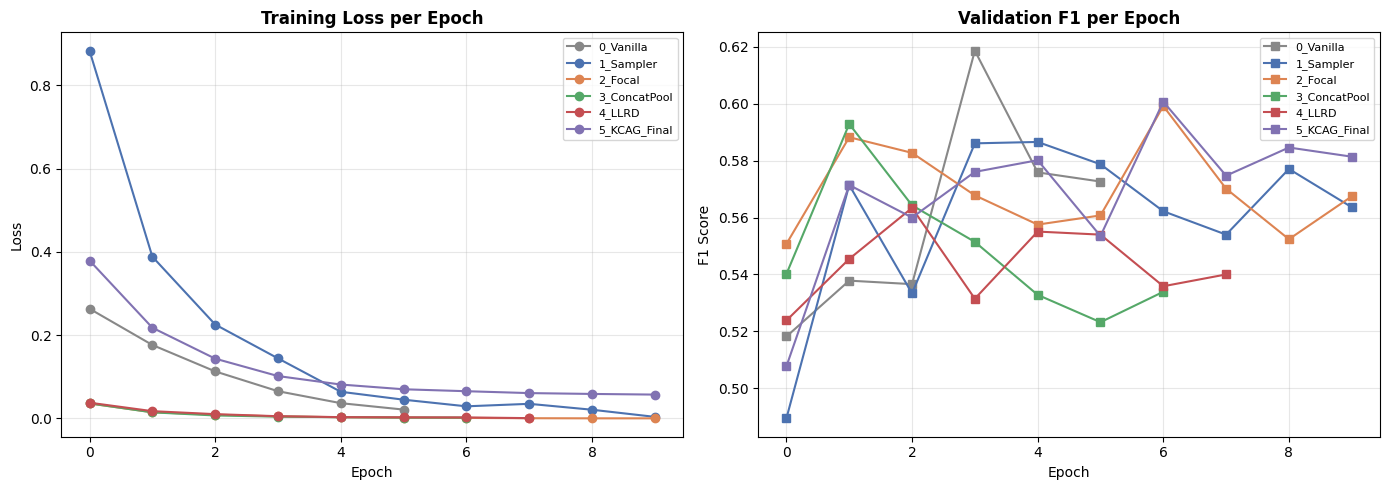

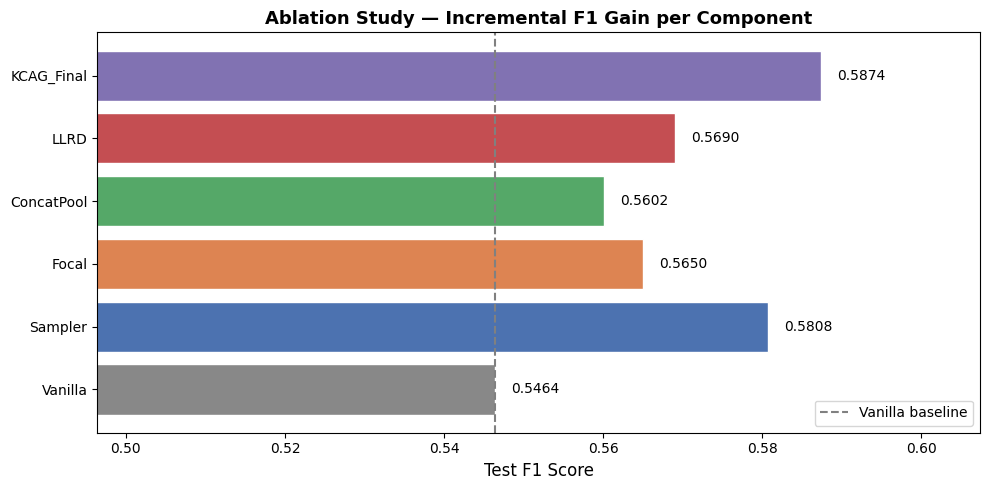

In [36]:
# ── Summary table ────────────────────────────────────────────────────────────
print("\n" + "="*60)
print("ABLATION SUMMARY TABLE")
print("="*60)
print(f"{'Experiment':<45} | {'Test F1':>7} | {'Δ vs prev':>9}")
print("-" * 65)
prev = None
for exp, f1 in sorted(results.items()):
    delta = f" +{f1-prev:.4f}" if prev is not None else "   —   "
    print(f"{exp:<45} | {f1:>7.4f} | {delta:>9}")
    prev = f1

# ── Training curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colours = ['#888888','#4C72B0','#DD8452','#55A868','#C44E52','#8172B2']
labels  = list(training_curves.keys())

for i, (label, curves) in enumerate(training_curves.items()):
    c = colours[i % len(colours)]
    axes[0].plot(curves['train_losses'], marker='o', color=c, label=label.split(':')[0])
    axes[1].plot(curves['val_f1s'],      marker='s', color=c, label=label.split(':')[0])

axes[0].set_title('Training Loss per Epoch', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

axes[1].set_title('Validation F1 per Epoch', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('F1 Score')
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Bar chart of ablation results ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
names = [k.split('_', 1)[1] for k in sorted(results.keys())]
vals  = [results[k] for k in sorted(results.keys())]
bars  = ax.barh(names, vals, color=colours[:len(vals)], edgecolor='white')
ax.axvline(x=vals[0], color='gray', ls='--', lw=1.5, label='Vanilla baseline')
ax.set_xlabel('Test F1 Score', fontsize=12); ax.set_xlim(max(0, min(vals)-0.05), max(vals)+0.02)
ax.set_title('Ablation Study — Incremental F1 Gain per Component', fontweight='bold', fontsize=13)
for bar, v in zip(bars, vals):
    ax.text(v + 0.002, bar.get_y() + bar.get_height()/2, f'{v:.4f}', va='center', fontsize=10)
ax.legend(); plt.tight_layout()
plt.savefig('ablation_bar.png', dpi=150, bbox_inches='tight')
plt.show()

## Precision-Recall Analysis

The PR curve is more informative than ROC at high class imbalance (91% negative).  
**Average Precision (AP)** is the area under the curve — a single-number summary.  
A random classifier at 9% positive rate would have AP ≈ 0.09.

GLOBAL METRICS (Best Model on Official Dev Set)
  True Positives  (TP): 126
  True Negatives  (TN): 1791
  False Positives (FP): 104
  False Negatives (FN): 73 
  FPR: 0.0549  |  FNR: 0.3668


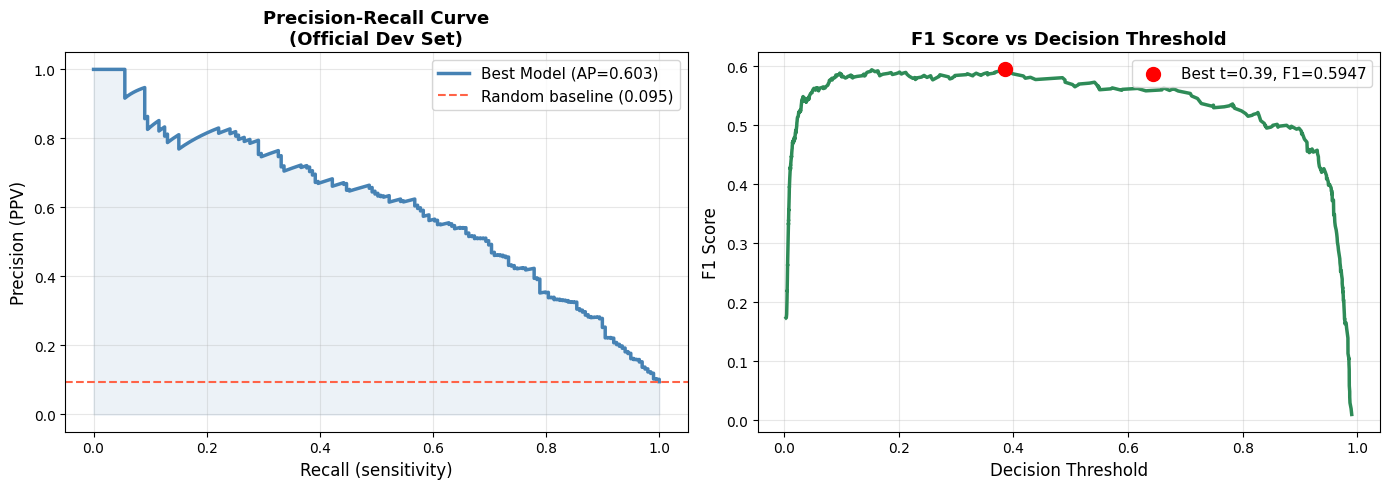

Average Precision (AP): 0.6027  (random baseline: 0.0950)


In [ ]:
analysis_df = pd.read_csv("best_predictions.csv")
analysis_df['text_word_count'] = analysis_df['text'].apply(lambda x: len(str(x).split()))

# ── Global confusion matrix metrics ──────────────────────────────────────────
cm = confusion_matrix(analysis_df['ground_truth_binary'], analysis_df['tamn_pred'])
tn, fp, fn, tp = cm.ravel()
fpr = fp / (fp + tn + 1e-9)
fnr = fn / (fn + tp + 1e-9)

print("="*55)
print("GLOBAL METRICS (Best Model on Official Dev Set)")
print("="*55)
print(f"  True Positives  (TP): {tp}")
print(f"  True Negatives  (TN): {tn}")
print(f"  False Positives (FP): {fp}")
print(f"  False Negatives (FN): {fn} ")
print(f"  FPR: {fpr:.4f}  |  FNR: {fnr:.4f}")

# ── PR Curve ──────────────────────────────────────────────────────────────────
precision, recall, thresholds = precision_recall_curve(
    analysis_df['ground_truth_binary'], analysis_df['tamn_prob']
)
ap_score        = average_precision_score(analysis_df['ground_truth_binary'], analysis_df['tamn_prob'])
random_baseline = analysis_df['ground_truth_binary'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: PR curve
axes[0].plot(recall, precision, lw=2.5, color='steelblue', label=f'Best Model (AP={ap_score:.3f})')
axes[0].axhline(random_baseline, color='tomato', ls='--', lw=1.5, label=f'Random baseline ({random_baseline:.3f})')
axes[0].fill_between(recall, precision, alpha=0.1, color='steelblue')
axes[0].set_xlabel('Recall (sensitivity)', fontsize=12)
axes[0].set_ylabel('Precision (PPV)', fontsize=12)
axes[0].set_title('Precision-Recall Curve\n(Official Dev Set)', fontweight='bold', fontsize=13)
axes[0].legend(fontsize=11); axes[0].grid(alpha=0.3)

# Right: F1 vs threshold
f1_scores = [f1_score(analysis_df['ground_truth_binary'],
                       (analysis_df['tamn_prob'] >= t).astype(int), zero_division=0)
             for t in thresholds]
axes[1].plot(thresholds, f1_scores, lw=2.5, color='seagreen')
best_idx = np.argmax(f1_scores)
axes[1].scatter([thresholds[best_idx]], [f1_scores[best_idx]], color='red', s=100, zorder=5,
                label=f'Best t={thresholds[best_idx]:.2f}, F1={f1_scores[best_idx]:.4f}')
axes[1].set_xlabel('Decision Threshold', fontsize=12)
axes[1].set_ylabel('F1 Score', fontsize=12)
axes[1].set_title('F1 Score vs Decision Threshold', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=11); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Average Precision (AP): {ap_score:.4f}  (random baseline: {random_baseline:.4f})")

## Error Analysis 1: Performance by Vulnerable Group Keyword

This table evaluates whether performance is consistent across the different
vulnerable group keywords in the dataset. High variance in per-keyword F1
suggests the model struggles with certain groups more than others.

Keyword                |     F1 |   Prec | Recall |     N |   %PCL
-----------------------------------------------------------------
disabled               | 0.5714 | 0.5714 | 0.5714 |   194 |   7.2%
homeless               | 0.5333 | 0.5161 | 0.5517 |   212 |  13.7%
hopeless               | 0.5091 | 0.4828 | 0.5385 |   217 |  12.0%
immigrant              | 0.6154 | 0.6667 | 0.5714 |   218 |   3.2%
in-need                | 0.7160 | 0.6042 | 0.8788 |   226 |  14.6%
migrant                | 0.6000 | 0.6000 | 0.6000 |   207 |   2.4%
poor-families          | 0.6494 | 0.6410 | 0.6579 |   190 |  20.0%
refugee                | 0.4516 | 0.3889 | 0.5385 |   188 |   6.9%
vulnerable             | 0.5217 | 0.4615 | 0.6000 |   209 |   9.6%
women                  | 0.5714 | 0.5714 | 0.5714 |   233 |   6.0%

F1 std across keywords: 0.0759


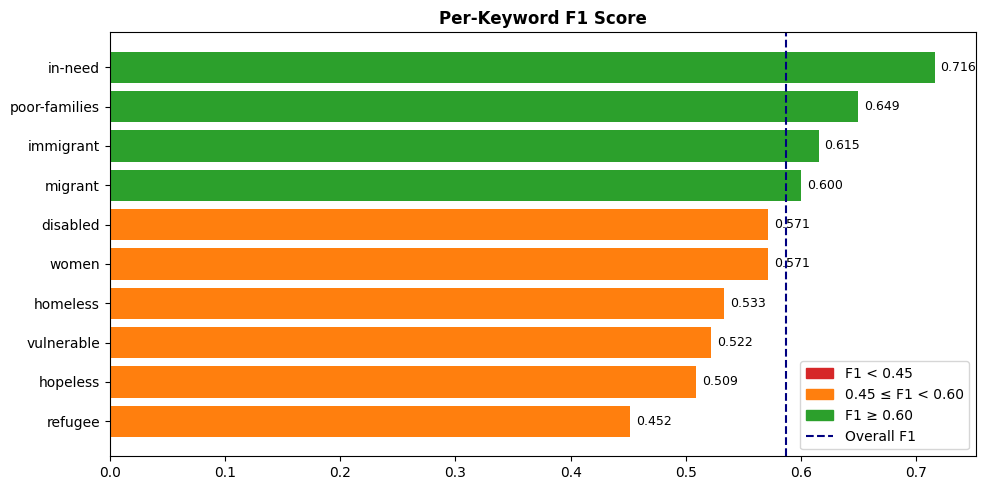

In [21]:

print(f"{'Keyword':<22} | {'F1':>6} | {'Prec':>6} | {'Recall':>6} | {'N':>5} | {'%PCL':>6}")
print("-"*65)

kw_results = []
for kw in sorted(analysis_df['keyword'].unique()):
    sub = analysis_df[analysis_df['keyword'] == kw]
    if len(sub) == 0: continue
    kw_f1  = f1_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    kw_p   = precision_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    kw_r   = recall_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    pct    = 100 * sub['ground_truth_binary'].mean()
    kw_results.append({'keyword': kw, 'F1': kw_f1, 'Precision': kw_p,
                        'Recall': kw_r, 'N': len(sub), 'PCL%': pct})
    print(f"{kw:<22} | {kw_f1:>6.4f} | {kw_p:>6.4f} | {kw_r:>6.4f} | {len(sub):>5} | {pct:>5.1f}%")

kw_df = pd.DataFrame(kw_results).sort_values('F1')
print(f"\nF1 std across keywords: {kw_df['F1'].std():.4f}")

# Visualise
fig, ax = plt.subplots(figsize=(10, 5))
colors_ = ['#D62728' if f < 0.45 else ('#FF7F0E' if f < 0.6 else '#2CA02C') for f in kw_df['F1']]
bars_ = ax.barh(kw_df['keyword'], kw_df['F1'], color=colors_)
ax.axvline(x=0.587, color='navy', ls='--', lw=1.5, label='Overall Test F1')
ax.set_title('Per-Keyword F1 Score', fontweight='bold')

red_p  = mpatches.Patch(color='#D62728', label='F1 < 0.45')
org_p  = mpatches.Patch(color='#FF7F0E', label='0.45 ≤ F1 < 0.60')
grn_p  = mpatches.Patch(color='#2CA02C', label='F1 ≥ 0.60')
ax.legend(handles=[red_p, org_p, grn_p, plt.Line2D([0],[0],color='navy',ls='--')],
          labels=['F1 < 0.45', '0.45 ≤ F1 < 0.60', 'F1 ≥ 0.60', 'Overall F1'])
for bar, v in zip(bars_, kw_df['F1']):
    ax.text(v+0.005, bar.get_y()+bar.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('keyword_f1.png', dpi=150, bbox_inches='tight')
plt.show()

##  Error Analysis 2: Severity-Stratified Recall

PCL ranges from borderline (severity 2) to strongly condescending (severity 4).  
A good model should catch *all* severity levels — dropping recall at severity 4 is a critical failure.

RECALL BY ANNOTATOR AGREEMENT LEVEL
Agreement Level          |  Recall |     N
----------------------------------------
Both borderline (1+1)    |  0.3333 |    18
Mixed agreement (2+1)    |  0.5730 |    89
Both clear PCL  (2+2)    |  0.7500 |    92


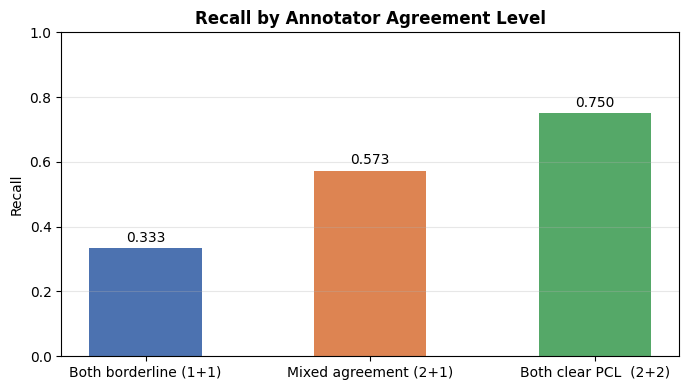

In [29]:
print("="*60)
print("RECALL BY ANNOTATOR AGREEMENT LEVEL")
print("="*60)
print(f"{'Agreement Level':<24} | {'Recall':>7} | {'N':>5}")
print("-"*40)

label_desc = {
    2: 'Both borderline (1+1)',
    3: 'Mixed agreement (2+1)',
    4: 'Both clear PCL  (2+2)',
}

sev_rows = []
for level in [2, 3, 4]:
    sub = analysis_df[analysis_df['original_severity_0_to_4'] == level]
    if len(sub) == 0: continue
    rec = recall_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    sev_rows.append({'Level': level, 'Desc': label_desc[level], 'Recall': rec, 'N': len(sub)})
    print(f"{label_desc[level]:<24} | {rec:>7.4f} | {len(sub):>5}")

sev_df = pd.DataFrame(sev_rows)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(sev_df['Desc'], sev_df['Recall'], color=['#4C72B0','#DD8452','#55A868'], width=0.5)
ax.set_ylim(0, 1.0)
ax.set_ylabel('Recall')
ax.set_title('Recall by Annotator Agreement Level', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
for bar, v in zip(bars, sev_df['Recall']):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}', ha='center', fontsize=10)
plt.tight_layout()
plt.savefig('severity_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## Error Analysis 3: Text-Length Context Dilution

TEXT-LENGTH CONTEXT DILUTION
Short (1-25 words)  : F1=0.6000 | Recall=0.7500 | P=0.5000 (359 samples)
Medium (26-60)      : F1=0.6009 | Recall=0.6481 | P=0.5600 (1254 samples)
Long (61+)          : F1=0.5588 | Recall=0.5672 | P=0.5507 (481 samples)


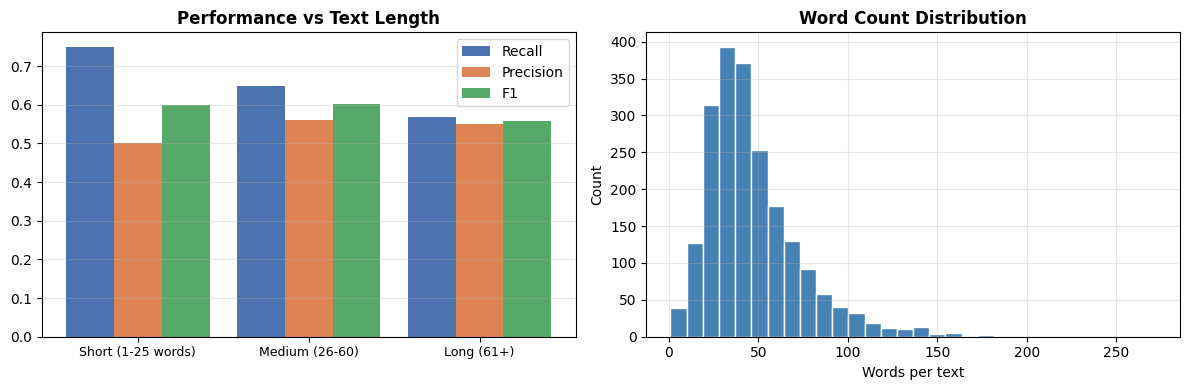

In [20]:
print("="*55)
print("TEXT-LENGTH CONTEXT DILUTION")
print("="*55)
bins_  = [0, 25, 60, np.inf]
lbls_  = ['Short (1-25 words)', 'Medium (26-60)', 'Long (61+)']
analysis_df['length_cat'] = pd.cut(analysis_df['text_word_count'], bins=bins_, labels=lbls_)

len_rows = []
for cat in lbls_:
    sub = analysis_df[analysis_df['length_cat'] == cat]
    if len(sub) == 0: continue
    f1_ = f1_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    rec = recall_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    prec= precision_score(sub['ground_truth_binary'], sub['tamn_pred'], zero_division=0)
    len_rows.append({'Category': cat, 'F1': f1_, 'Recall': rec, 'Precision': prec, 'N': len(sub)})
    print(f"{cat:<20}: F1={f1_:.4f} | Recall={rec:.4f} | P={prec:.4f} ({len(sub)} samples)")

len_df = pd.DataFrame(len_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x_ = np.arange(len(len_df)); w_ = 0.28
axes[0].bar(x_-w_, len_df['Recall'],    width=w_, label='Recall', color='#4C72B0')
axes[0].bar(x_,    len_df['Precision'], width=w_, label='Precision', color='#DD8452')
axes[0].bar(x_+w_, len_df['F1'],        width=w_, label='F1', color='#55A868')
axes[0].set_xticks(x_); axes[0].set_xticklabels(len_df['Category'], fontsize=9)
axes[0].set_title('Performance vs Text Length', fontweight='bold'); axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
axes[1].hist(analysis_df['text_word_count'], bins=30, color='steelblue', edgecolor='white')
axes[1].set_title('Word Count Distribution', fontweight='bold')
axes[1].set_xlabel('Words per text'); axes[1].set_ylabel('Count'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('length_analysis.png', dpi=150, bbox_inches='tight'); plt.show()

## Qualitative Error Sampling

Four representative failure/success scenarios

In [34]:
def get_sample(df, cond, title):
    sub = df[cond]
    if sub.empty:
        print(f"\n{title}\n  (no matching samples)")
        return
    s = sub.sample(1, random_state=42).iloc[0]
    print(f"\n{'─'*65}")
    print(f"  {title}")
    print(f"  Keyword  : {s['keyword']}   Severity: {s['original_severity_0_to_4']}   p(PCL)={s['tamn_prob']:.3f}")
    print(f"  Text     : {str(s['text'])[:280]}")

get_sample(analysis_df,
    (analysis_df['error_type']=='False Positive') & (analysis_df['text_word_count'] < 30),
    "[A] Lexical Hallucination — FP on Short Text")

get_sample(analysis_df,
    (analysis_df['error_type']=='False Negative') & (analysis_df['original_severity_0_to_4']==4),
    "[B] Implicit Condescension — FN on Severity 4")
get_sample(analysis_df,
    (analysis_df['error_type']=='False Negative') & (analysis_df['text_word_count'] > 60),
    "[C] Context Dilution — FN on Long Text")
get_sample(analysis_df,
    (analysis_df['error_type']=='True Positive') & (analysis_df['original_severity_0_to_4']==2),
    "[D] KCAG Win — TP on Subtle Severity 2 (what baseline misses)")


─────────────────────────────────────────────────────────────────
  [A] Lexical Hallucination — FP on Short Text
  Keyword  : vulnerable   Severity: 1   p(PCL)=0.249
  Text     : Govt urged to support vulnerable children

─────────────────────────────────────────────────────────────────
  [B] Implicit Condescension — FN on Severity 4
  Keyword  : homeless   Severity: 4   p(PCL)=0.058
  Text     : With a mission to " strive every day to create a safe haven where homeless women and children find stability and access to the basic needs of life " , the Elfreeda Foundation launched its open shelter on the 11th of August 2017 . In attendance were dignitaries such as : the wife 

─────────────────────────────────────────────────────────────────
  [C] Context Dilution — FN on Long Text
  Keyword  : hopeless   Severity: 4   p(PCL)=0.021
  Text     : It is seen in recurring violence and continuing degradation of women through stone-age practices such as FGM . It is seen in the thousands of Afri

In [ ]:
baseline_df = pd.read_csv('vanilla_predictions.csv')
best_df     = pd.read_csv('best_predictions.csv')

compare = baseline_df.copy()
compare['best_pred'] = best_df['tamn_pred']

# baseline wrong, best model right
wins = compare[
    (compare['ground_truth_binary'] == 1) &
    (compare['tamn_pred'] == 0) &        # baseline FN
    (compare['best_pred'] == 1)           # best model TP
][['text', 'keyword', 'original_severity_0_to_4']].head(10)

print(wins.to_string())

                                                                                                                                                                                                                                                                                                                                                                   text        keyword  original_severity_0_to_4
8                                                                           " People do n't understand the hurt , people do n't understand the pain . I 've read about women with their children sleeping in cars , sleeping in hotel rooms and it 's criminal . If they 're lucky and they come across COPE Galway and the ladies in Osterley , then there 's hope . "          women                         4
16                                                                                                                                                                                                    

Keyword            |     N |  Base F1 |  Best F1 |    F1 Δ |  Wins |  Loses |  Wins %
-------------------------------------------------------------------------------------
immigrant          |   218 |   0.0000 |   0.6154 | +0.6154 |     4 |      0 |    1.8%
women              |   233 |   0.4000 |   0.5714 | +0.1714 |     6 |      3 |    2.6%
poor-families      |   190 |   0.4928 |   0.6494 | +0.1566 |     9 |      1 |    4.7%
migrant            |   207 |   0.5000 |   0.6000 | +0.1000 |     1 |      0 |    0.5%
vulnerable         |   209 |   0.4878 |   0.5217 | +0.0339 |     2 |      0 |    1.0%
hopeless           |   217 |   0.5098 |   0.5091 | -0.0007 |     3 |      2 |    1.4%
disabled           |   194 |   0.5833 |   0.5714 | -0.0119 |     1 |      0 |    0.5%
in-need            |   226 |   0.7317 |   0.7160 | -0.0157 |     2 |      3 |    0.9%
refugee            |   188 |   0.4800 |   0.4516 | -0.0284 |     2 |      1 |    1.1%
homeless           |   212 |   0.5818 |   0.5333 | -0.

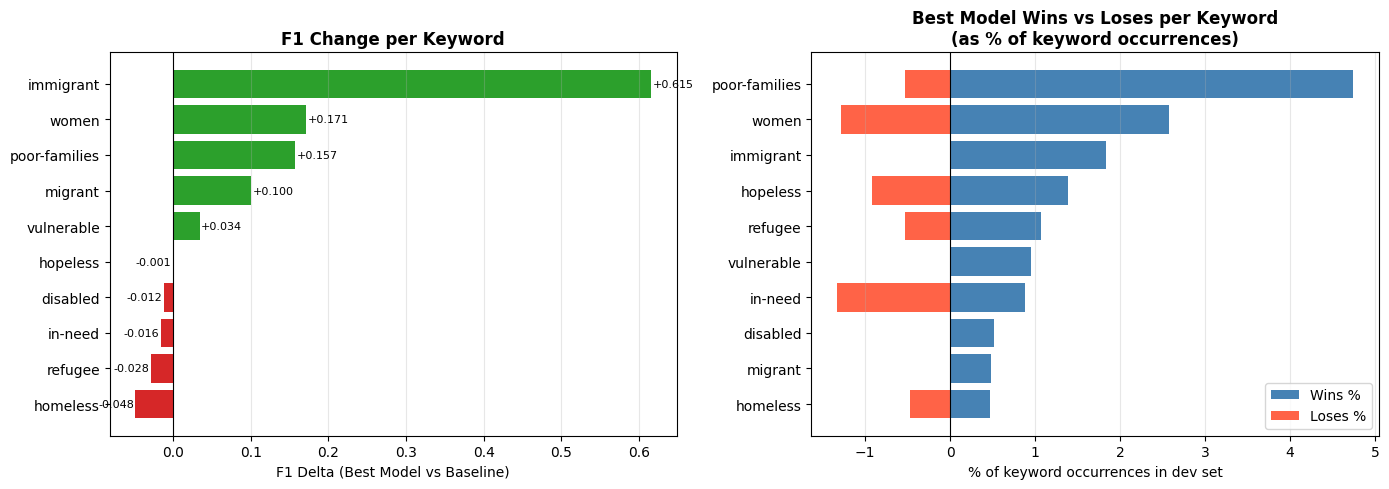

In [36]:
baseline_df = pd.read_csv('vanilla_predictions.csv')
best_df     = pd.read_csv('best_predictions.csv')

compare = baseline_df.copy()
compare['best_pred'] = best_df['tamn_pred']

# ── Per-keyword improvement ───────────────────────────────────────────────────
rows = []
for kw in sorted(compare['keyword'].unique()):
    sub = compare[compare['keyword'] == kw]
    n   = len(sub)

    # cases where best model wins (baseline FN, best TP)
    wins  = ((sub['ground_truth_binary'] == 1) &
             (sub['tamn_pred'] == 0) &
             (sub['best_pred'] == 1)).sum()

    # cases where baseline wins (baseline TP, best FN)
    loses = ((sub['ground_truth_binary'] == 1) &
             (sub['tamn_pred'] == 1) &
             (sub['best_pred'] == 0)).sum()

    base_f1 = f1_score(sub['ground_truth_binary'], sub['tamn_pred'],  zero_division=0)
    best_f1 = f1_score(sub['ground_truth_binary'], sub['best_pred'],  zero_division=0)

    rows.append({
        'keyword':   kw,
        'N':         n,
        'wins':      wins,
        'loses':     loses,
        'net_gains': wins - loses,
        'wins_pct':  100 * wins  / n,
        'loses_pct': 100 * loses / n,
        'baseline_f1': base_f1,
        'best_f1':     best_f1,
        'f1_delta':    best_f1 - base_f1,
    })

kw_compare = pd.DataFrame(rows).sort_values('f1_delta', ascending=False)

print(f"{'Keyword':<18} | {'N':>5} | {'Base F1':>8} | {'Best F1':>8} | {'F1 Δ':>7} | {'Wins':>5} | {'Loses':>6} | {'Wins %':>7}")
print("-" * 85)
for _, r in kw_compare.iterrows():
    print(f"{r['keyword']:<18} | {r['N']:>5} | {r['baseline_f1']:>8.4f} | {r['best_f1']:>8.4f} | "
          f"{r['f1_delta']:>+7.4f} | {r['wins']:>5} | {r['loses']:>6} | {r['wins_pct']:>6.1f}%")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

kw_sorted_delta = kw_compare.sort_values('f1_delta')
colors_ = ['#2CA02C' if v >= 0 else '#D62728' for v in kw_sorted_delta['f1_delta']]

axes[0].barh(kw_sorted_delta['keyword'], kw_sorted_delta['f1_delta'], color=colors_)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_xlabel('F1 Delta (Best Model vs Baseline)')
axes[0].set_title('F1 Change per Keyword', fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)
for i, (_, r) in enumerate(kw_sorted_delta.iterrows()):
    axes[0].text(r['f1_delta'] + (0.002 if r['f1_delta'] >= 0 else -0.002),
                 i, f"{r['f1_delta']:+.3f}", va='center',
                 ha='left' if r['f1_delta'] >= 0 else 'right', fontsize=8)

kw_sorted_wins = kw_compare.sort_values('wins_pct')
axes[1].barh(kw_sorted_wins['keyword'], kw_sorted_wins['wins_pct'], color='steelblue', label='Wins %')
axes[1].barh(kw_sorted_wins['keyword'], [-v for v in kw_sorted_wins['loses_pct']],
             color='tomato', label='Loses %')
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_xlabel('% of keyword occurrences in dev set')
axes[1].set_title('Best Model Wins vs Loses per Keyword\n(as % of keyword occurrences)', fontweight='bold')
axes[1].legend(); axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('keyword_improvement.png', dpi=150, bbox_inches='tight')
plt.show()

## Inference Output (Submission)

In [24]:
class InferenceDataset(Dataset):
    def __init__(self, df, tokenizer, flags, max_length=192):
        self.texts     = df['text'].fillna("").tolist()
        self.keywords  = df['keyword'].fillna("none").tolist()
        self.tokenizer = tokenizer
        self.flags     = flags
        self.max_length = max_length

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        kw   = str(self.keywords[idx]).replace('-',' ').lower().strip()
        if kw in ('nan','none',''): kw = 'vulnerable group'
        if self.flags.get('use_entity_markers', False):
            pat = re.compile(f'(?i)({re.escape(kw)})')
            text = pat.sub(r'[E1] \1 [/E1]', text) if pat.search(text) else f"[E1] {kw} [/E1] : {text}"
        elif self.flags.get('include_keyword_context', False):
            text = f"{kw} </s></s> {text}"
        enc    = self.tokenizer(text, truncation=True, padding='max_length',
                                max_length=self.max_length, return_tensors='pt')
        kw_enc = self.tokenizer(kw,   truncation=True, padding='max_length',
                                max_length=16, return_tensors='pt')
        return {
            'input_ids': enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'kw_input_ids': kw_enc['input_ids'].flatten(),
            'kw_attention_mask': kw_enc['attention_mask'].flatten(),
        }


def write_predictions(model, df, tokenizer, flags, threshold, filename, batch_size=32, max_length=192):
    model.eval()
    dl   = DataLoader(InferenceDataset(df, tokenizer, flags, max_length), batch_size=batch_size, shuffle=False)
    preds = []
    with torch.no_grad():
        for b in tqdm(dl, desc=f"→ {filename}"):
            logits, _, _ = model(b['input_ids'].to(device), b['attention_mask'].to(device),
                                  b['kw_input_ids'].to(device), b['kw_attention_mask'].to(device))
            preds.extend((torch.sigmoid(logits).cpu().numpy() >= threshold).astype(int))
    with open(filename, 'w') as f:
        for p in preds: f.write(f"{p}\n")
    print(f"Saved {len(preds)} predictions → {filename}")


# Reload
tok_inf = AutoTokenizer.from_pretrained('roberta-base')
if final_flags.get('use_entity_markers', False): tok_inf.add_tokens(['[E1]', '[/E1]'])
inf_model = ModularModel('roberta-base', len(tok_inf), final_flags, base_config).to(device)
inf_model.load_state_dict(torch.load('best_model.pt', map_location=device, weights_only=True))

dvids            = pd.read_csv('../data/dev_semeval_parids-labels.csv')
dvids['par_id']  = dvids['par_id'].astype(str)
dev_inf_df       = pd.merge(dvids[['par_id']], df_raw, on='par_id', how='left')
test_inf_df      = pd.read_csv('../data/task4_test.tsv', sep='\t',
                               names=['par_id','art_id','keyword','country_code','text'],
                               on_bad_lines='skip')

write_predictions(inf_model, dev_inf_df,  tok_inf, final_flags, optimal_threshold, 'dev.txt')
write_predictions(inf_model, test_inf_df, tok_inf, final_flags, optimal_threshold, 'test.txt')

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 338.95it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
→ dev.txt: 100%|██████████| 66/66 [00:17<00:00,  3.82it/s]


Saved 2094 predictions → dev.txt


→ test.txt: 100%|██████████| 120/120 [00:32<00:00,  3.73it/s]


Saved 3832 predictions → test.txt
